# Lista 2: Inteligência Artificial (UFAL)
## Questão 8: Sistema de Diagnóstico Médico com Redes Bayesianas

**Dupla:**
- Bruno Gomes de Barros Filho, matrícula 21111360
- Antônio Rodrigo Lima de Andrade Tenório, matrícula 23210707

**Disciplina:** ECOM031: Inteligência Artificial
**Professor:** Evandro de Barros Costa
**Período:** 2026.2

---

### Enunciado (Q8)
> Desenvolva de um Sistema de Diagnóstico Médico Utilizando Redes Bayesianas. Trata-se de uma atividade na qual se aplicará os conceitos de Representação do Conhecimento sob Incerteza por meio da modelagem e implementação de um sistema inteligente de diagnóstico médico baseado em Redes Bayesianas. Cada equipe deverá desenvolver um modelo probabilístico capaz de representar relações de dependência entre doenças, sintomas e outros fatores relevantes, permitindo a realização de inferências diagnósticas a partir das evidências observadas. O sistema deverá utilizar uma Rede Bayesiana para:
> a) Modelar relações de causa e efeito entre doenças e sintomas;
> b) Realizar inferências diagnósticas diante de evidências incompletas ou incertas;
> c) Atualizar probabilidades à medida que novas evidências forem fornecidas.
>
> Requisitos mínimos: pelo menos uma doença principal; no mínimo cinco variáveis; pelo menos três sintomas observáveis; relações de dependência justificadas; CPTs associadas aos nós; representação gráfica da rede. Descrever o domínio, o significado de cada variável, as hipóteses, a justificativa das probabilidades e as independências condicionais representadas. Implementar em ferramenta apropriada (Netica, GeNIe, BayesiaLab, Python/pgmpy...). Realizar pelo menos três experimentos de inferência (evidências, priori, posteriori, interpretação), por exemplo Febre = Sim, depois Tosse = Sim, depois Dor muscular = Sim, mostrando a atualização da probabilidade da doença. Discutir como a rede representa a incerteza, a influência de cada evidência, as vantagens sobre sistemas só de regras, as limitações e as possíveis melhorias.

O relatório completo está no `README.md` desta pasta. Este notebook importa os módulos `rede_dengue.py` (estrutura, CPTs, exportação) e `inferencia_bayes.py` (consultas) e percorre a solução passo a passo.

## 0. Imports

Os pacotes vêm do ambiente do repositório (`.venv`). O pgmpy instalado é da série 1.1, em que a classe se chama `DiscreteBayesianNetwork`.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pgmpy
from pgmpy.inference import VariableElimination

from inferencia_bayes import (
    atualizacao_incremental, distribuicao, enumeracao_manual, estimar_por_amostragem,
    evidencia_incerta, valor_da_informacao,
)
from rede_dengue import ARESTAS, DESCRICOES, FORMATOS, TIPOS, construir_rede, exportar_rede, ler_rede

FIGURAS = Path("figures")
FIGURAS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})

# paleta categórica fixa: Dengue sempre azul, Influenza sempre laranja
AZUL, LARANJA, VERDE, AMARELO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
print("pgmpy", pgmpy.__version__)

pgmpy 1.1.2


## 1. Domínio e variáveis

Domínio: triagem de pacientes com quadro febril agudo numa unidade de pronto atendimento em Alagoas, onde a dengue é endêmica e convive com outras viroses. A doença principal é a **dengue**. A **influenza** entra como diagnóstico concorrente, porque também dá febre e dor no corpo; é ela que permite mostrar o efeito *explaining away*.

São 10 variáveis discretas: 2 fatores de contexto/risco, 2 doenças, 5 sintomas e 1 exame de beira de leito.

In [2]:
rede = construir_rede()
ve = VariableElimination(rede)

variaveis = pd.DataFrame({
    "tipo": TIPOS,
    "estados": {no: " / ".join(rede.get_cpds(no).state_names[no]) for no in DESCRICOES},
    "pais": {no: ", ".join(rede.get_parents(no)) or "-" for no in DESCRICOES},
    "significado": DESCRICOES,
})
variaveis

,tipo,estados,pais,significado
Estacao,fator de contexto,Chuvosa / Seca,-,Período do ano em Alagoas: Chuvosa (cerca de a...
Exposicao,fator de risco,Sim / Nao,Estacao,Paciente mora ou circula perto de foco do Aede...
Dengue,doença,Sim / Nao,Exposicao,Paciente está com dengue (doença principal)
Influenza,doença,Sim / Nao,Estacao,Paciente está com gripe (diagnóstico concorrente)
Febre,sintoma,Sim / Nao,"Dengue, Influenza",Febre aferida ou relatada (>= 38 °C)
DorMuscular,sintoma,Sim / Nao,"Dengue, Influenza",Mialgia (dor no corpo)
Tosse,sintoma,Sim / Nao,Influenza,Tosse
DorRetroOrbital,sintoma,Sim / Nao,Dengue,Dor atrás dos olhos
Manchas,sintoma,Sim / Nao,Dengue,Exantema (manchas vermelhas na pele)
ProvaLaco,exame,Sim / Nao,Dengue,Prova do laço positiva (exame de beira de leito)


## 2. Estrutura da rede

As arestas seguem a direção causal: o período chuvoso aumenta a chance de haver criadouros do *Aedes* perto do paciente e também a circulação de vírus respiratórios; a exposição ao mosquito causa a dengue; cada doença causa seus sintomas. Febre e dor muscular têm dois pais porque as duas doenças as provocam. Tosse depende só da influenza; dor retro-orbital, manchas e prova do laço dependem só da dengue.

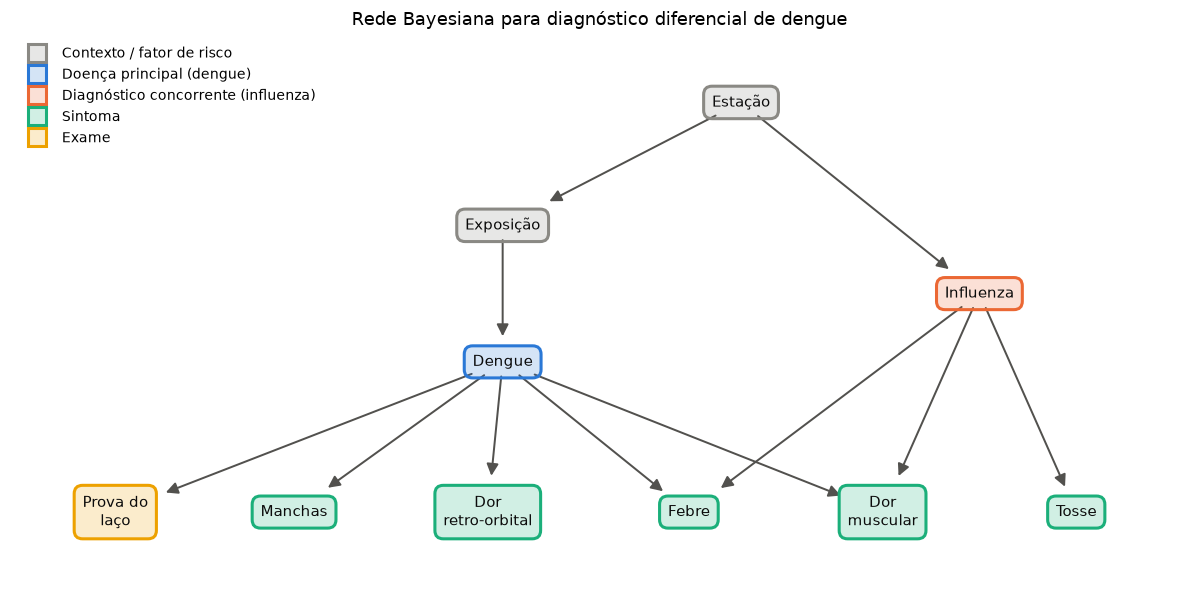

In [3]:
cores_tipo = {"fator de contexto": CINZA, "fator de risco": CINZA, "doença": None, "sintoma": VERDE, "exame": AMARELO}
cor_no = {no: cores_tipo[t] for no, t in TIPOS.items()}
cor_no.update({"Dengue": AZUL, "Influenza": LARANJA})

posicoes = {
    "Estacao": (0.6, 3), "Exposicao": (-1.0, 2.1), "Dengue": (-1.0, 1.1), "Influenza": (2.2, 1.6),
    "ProvaLaco": (-3.6, 0), "Manchas": (-2.4, 0), "DorRetroOrbital": (-1.1, 0),
    "Febre": (0.25, 0), "DorMuscular": (1.55, 0), "Tosse": (2.85, 0),
}
rotulos = {no: {"DorRetroOrbital": "Dor\nretro-orbital", "DorMuscular": "Dor\nmuscular",
                "ProvaLaco": "Prova do\nlaço", "Estacao": "Estação", "Exposicao": "Exposição"}.get(no, no)
           for no in rede.nodes()}

fig, ax = plt.subplots(figsize=(11, 5.6))
caixas = {}
for no, (x, y) in posicoes.items():
    caixas[no] = ax.text(x, y, rotulos[no], ha="center", va="center", fontsize=10, color="#0b0b0b", zorder=3,
                         bbox=dict(boxstyle="round,pad=0.55", fc=cor_no[no] + "33", ec=cor_no[no], lw=2))
for pai, filho in ARESTAS:
    # patchA/patchB fazem a seta começar e terminar na borda de cada caixa
    ax.annotate("", xy=posicoes[filho], xytext=posicoes[pai], zorder=2, arrowprops=dict(
        arrowstyle="-|>", color="#52514e", lw=1.3, mutation_scale=16, shrinkA=2, shrinkB=2,
        patchA=caixas[pai].get_bbox_patch(), patchB=caixas[filho].get_bbox_patch()))
legenda = [plt.Line2D([], [], marker="s", ls="", ms=12, mfc=c + "33", mec=c, mew=2, label=l) for c, l in
           [(CINZA, "Contexto / fator de risco"), (AZUL, "Doença principal (dengue)"),
            (LARANJA, "Diagnóstico concorrente (influenza)"), (VERDE, "Sintoma"), (AMARELO, "Exame")]]
ax.legend(handles=legenda, loc="upper left", frameon=False, fontsize=9)
ax.set_title("Rede Bayesiana para diagnóstico diferencial de dengue")
ax.set_xlim(-4.3, 3.6); ax.set_ylim(-0.6, 3.5); ax.axis("off")
fig.tight_layout(); fig.savefig(FIGURAS / "q08_rede.png", bbox_inches="tight")
plt.show()

## 3. Tabelas de probabilidades condicionais (CPTs)

Cada linha é uma combinação de estados dos pais e as colunas são os estados do nó (`to_dataframe` do pgmpy ordena os estados em ordem alfabética, por isso `Nao` aparece antes de `Sim`). Todas as linhas somam 1, o que `check_model()` já verificou ao construir a rede.

In [4]:
for no in ["Estacao", "Exposicao", "Influenza", "Dengue", "Febre", "DorMuscular", "Tosse", "DorRetroOrbital", "Manchas", "ProvaLaco"]:
    cpd = rede.get_cpds(no)
    pais = rede.get_parents(no)
    tabela = cpd.to_dataframe() if pais else pd.DataFrame([cpd.get_values()[:, 0]], columns=cpd.state_names[no], index=["(sem pais)"])
    print(f"P({no}" + (f" | {', '.join(pais)})" if pais else ")"))
    display(tabela)

P(Estacao)


,Chuvosa,Seca
(sem pais),0.4000,0.6000


P(Exposicao | Estacao)


Exposicao,Nao,Sim
Estacao,,
Chuvosa,0.4000,0.6000
Seca,0.7500,0.2500


P(Influenza | Estacao)


Influenza,Nao,Sim
Estacao,,
Chuvosa,0.8000,0.2000
Seca,0.9200,0.0800


... (10 outputs left out)

P(Manchas | Dengue)


Manchas,Nao,Sim
Dengue,,
Nao,0.9500,0.0500
Sim,0.5500,0.4500


P(ProvaLaco | Dengue)


ProvaLaco,Nao,Sim
Dengue,,
Nao,0.9500,0.0500
Sim,0.6000,0.4000


### Conferência de uma priori à mão

Antes de usar o motor de inferência, vale conferir uma conta simples. Pela regra da probabilidade total:

$P(\text{Exposição}) = 0{,}4 \cdot 0{,}6 + 0{,}6 \cdot 0{,}25 = 0{,}39$

$P(\text{Dengue}) = 0{,}39 \cdot 0{,}20 + 0{,}61 \cdot 0{,}03 = 0{,}0963$

In [5]:
print("P(Dengue=Sim) à mão      :", 0.39 * 0.20 + 0.61 * 0.03)
print("P(Dengue=Sim) pelo pgmpy :", distribuicao(ve, "Dengue")["Sim"])

P(Dengue=Sim) à mão      : 0.09630000000000001
P(Dengue=Sim) pelo pgmpy : 0.09630000000000001


## 4. Independências condicionais e d-separação

Cada nó é independente dos seus não descendentes dado os pais (propriedade de Markov local). O pgmpy lista essas independências com `local_independencies`.

In [6]:
for no in rede.nodes():
    print(rede.local_independencies(no))


(Exposicao ⟂ Influenza, Tosse | Estacao)
(Influenza ⟂ Dengue, DorRetroOrbital, Exposicao, Manchas, ProvaLaco | Estacao)
(Dengue ⟂ Estacao, Influenza, Tosse | Exposicao)
(Febre ⟂ DorMuscular, DorRetroOrbital, Estacao, Exposicao, Manchas, ProvaLaco, Tosse | Dengue, Influenza)
(DorMuscular ⟂ DorRetroOrbital, Estacao, Exposicao, Febre, Manchas, ProvaLaco, Tosse | Dengue, Influenza)
(Tosse ⟂ Dengue, DorMuscular, DorRetroOrbital, Estacao, Exposicao, Febre, Manchas, ProvaLaco | Influenza)
(DorRetroOrbital ⟂ DorMuscular, Estacao, Exposicao, Febre, Influenza, Manchas, ProvaLaco, Tosse | Dengue)
(Manchas ⟂ DorMuscular, DorRetroOrbital, Estacao, Exposicao, Febre, Influenza, ProvaLaco, Tosse | Dengue)
(ProvaLaco ⟂ DorMuscular, DorRetroOrbital, Estacao, Exposicao, Febre, Influenza, Manchas, Tosse | Dengue)


A d-separação mostra o que muda quando observamos algo. Testamos alguns pares com `is_dconnected` (True = existe caminho ativo, as variáveis podem se influenciar; False = d-separadas, independentes dado o conjunto observado).

In [7]:
casos = [
    ("Dengue", "Influenza", [], "caminho Dengue <- Exposição <- Estação -> Influenza está aberto"),
    ("Dengue", "Influenza", ["Estacao"], "observar a estação bloqueia o único caminho aberto"),
    ("Dengue", "Influenza", ["Estacao", "Febre"], "Febre é colisor: observá-la abre o caminho (explaining away)"),
    ("Dengue", "Influenza", ["Estacao", "DorMuscular"], "DorMuscular também é colisor"),
    ("Manchas", "DorRetroOrbital", [], "sintomas de causa comum são dependentes"),
    ("Manchas", "DorRetroOrbital", ["Dengue"], "dada a dengue, um sintoma nada diz sobre o outro"),
    ("Estacao", "Dengue", ["Exposicao"], "a estação só age sobre a dengue via exposição"),
    ("Tosse", "Manchas", [], "ligadas por Tosse <- Influenza <- Estação -> Exposição -> Dengue -> Manchas"),
    ("Tosse", "Manchas", ["Estacao"], "bloqueado na estação; Febre (colisor) não observada"),
    ("Tosse", "Manchas", ["Estacao", "Febre"], "observar Febre liga os dois ramos"),
]
pd.DataFrame(
    [(f"{a} e {b}", ", ".join(obs) or "(nada)", rede.is_dconnected(a, b, observed=obs), nota) for a, b, obs, nota in casos],
    columns=["par", "observado", "d-conectados?", "por quê"],
)

,par,observado,d-conectados?,por quê
0,Dengue e Influenza,(nada),True,caminho Dengue <- Exposição <- Estação -> Infl...
1,Dengue e Influenza,Estacao,False,observar a estação bloqueia o único caminho ab...
2,Dengue e Influenza,"Estacao, Febre",True,Febre é colisor: observá-la abre o caminho (ex...
3,Dengue e Influenza,"Estacao, DorMuscular",True,DorMuscular também é colisor
4,Manchas e DorRetroOrbital,(nada),True,sintomas de causa comum são dependentes
5,Manchas e DorRetroOrbital,Dengue,False,"dada a dengue, um sintoma nada diz sobre o outro"
6,Estacao e Dengue,Exposicao,False,a estação só age sobre a dengue via exposição
7,Tosse e Manchas,(nada),True,ligadas por Tosse <- Influenza <- Estação -> E...
8,Tosse e Manchas,Estacao,False,bloqueado na estação; Febre (colisor) não obse...
9,Tosse e Manchas,"Estacao, Febre",True,observar Febre liga os dois ramos


### Explaining away em números

Influenza e Dengue são independentes dada a estação. Quando a febre é observada, as duas viram explicações concorrentes: confirmar uma diminui a probabilidade da outra.

In [8]:
cenarios_ea = {
    "Estação seca": {"Estacao": "Seca"},
    "Estação seca + Febre": {"Estacao": "Seca", "Febre": "Sim"},
    "Estação seca + Febre + Dengue=Sim": {"Estacao": "Seca", "Febre": "Sim", "Dengue": "Sim"},
    "Estação seca + Febre + Dengue=Nao": {"Estacao": "Seca", "Febre": "Sim", "Dengue": "Nao"},
    "Estação seca + Dengue=Sim (sem Febre)": {"Estacao": "Seca", "Dengue": "Sim"},
}
pd.Series({nome: distribuicao(ve, "Influenza", ev)["Sim"] for nome, ev in cenarios_ea.items()}, name="P(Influenza=Sim)").to_frame()

,P(Influenza=Sim)
Estação seca,0.0800
Estação seca + Febre,0.2967
Estação seca + Febre + Dengue=Sim,0.0865
Estação seca + Febre + Dengue=Nao,0.3947
Estação seca + Dengue=Sim (sem Febre),0.0800


## 5. Experimento 1: diagnóstico a partir de sintomas típicos

Evidências: Febre = Sim, Dor retro-orbital = Sim, Manchas = Sim. Nenhum fator de contexto é informado (evidência incompleta). A tabela mostra priori e posteriori de todas as variáveis não observadas, inclusive de sintomas que ainda não foram perguntados.

In [9]:
ev1 = {"Febre": "Sim", "DorRetroOrbital": "Sim", "Manchas": "Sim"}
# primeiro estado de cada nó: "Sim", ou "Chuvosa" para a estação
alvo_estado = {no: rede.get_cpds(no).state_names[no][0] for no in rede.nodes() if no not in ev1}
exp1 = pd.DataFrame({
    "estado": alvo_estado,
    "priori": {no: distribuicao(ve, no)[e] for no, e in alvo_estado.items()},
    "posteriori": {no: distribuicao(ve, no, ev1)[e] for no, e in alvo_estado.items()},
})
exp1["razão"] = exp1["posteriori"] / exp1["priori"]
exp1

,estado,priori,posteriori,razão
Estacao,Chuvosa,0.4000,0.5498,1.3745
Exposicao,Sim,0.3900,0.8032,2.0595
Influenza,Sim,0.1280,0.1629,1.2727
Dengue,Sim,0.0963,0.9830,10.2072
DorMuscular,Sim,0.2774,0.8169,2.9451
Tosse,Sim,0.2332,0.2559,1.0973
ProvaLaco,Sim,0.0837,0.3940,4.7074


### Conferência por enumeração completa (numpy)

`enumeracao_manual` monta a distribuição conjunta das 10 variáveis ($2^{10} = 1024$ células) como produto das CPTs com `np.einsum`, fixa as evidências, soma as variáveis ocultas e normaliza. Esse cálculo não usa nenhum algoritmo de inferência do pgmpy, então serve de prova independente do resultado do Variable Elimination.

In [10]:
pd.DataFrame({
    "Variable Elimination": distribuicao(ve, "Dengue", ev1),
    "Enumeração (numpy)": enumeracao_manual(rede, "Dengue", ev1),
}).assign(diferença=lambda d: (d.iloc[:, 0] - d.iloc[:, 1]).abs())

,Variable Elimination,Enumeração (numpy),diferença
Sim,0.9830,0.9830,0.0000
Nao,0.0170,0.0170,0.0000


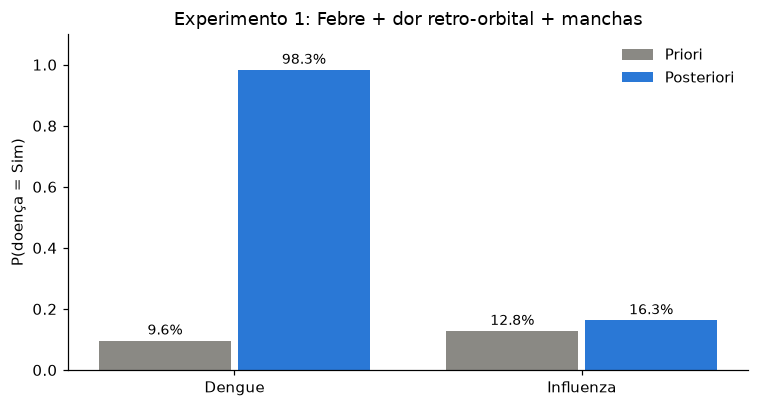

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
doencas = ["Dengue", "Influenza"]
x = np.arange(len(doencas))
pri = [exp1.loc[d, "priori"] for d in doencas]
pos = [exp1.loc[d, "posteriori"] for d in doencas]
ax.bar(x - 0.2, pri, 0.38, color=CINZA, label="Priori")
ax.bar(x + 0.2, pos, 0.38, color=AZUL, label="Posteriori")
for xi, (a, b) in enumerate(zip(pri, pos)):
    ax.text(xi - 0.2, a + 0.02, f"{a:.1%}", ha="center", fontsize=9)
    ax.text(xi + 0.2, b + 0.02, f"{b:.1%}", ha="center", fontsize=9)
ax.set_xticks(x, doencas); ax.set_ylim(0, 1.1); ax.set_ylabel("P(doença = Sim)")
ax.set_title("Experimento 1: Febre + dor retro-orbital + manchas")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGURAS / "q08_exp1_priori_posteriori.png", bbox_inches="tight")
plt.show()

## 6. Experimento 2: atualização incremental do diagnóstico

Sequência A é a do enunciado: Febre, depois Tosse, depois Dor muscular. Sequência B acrescenta sinais típicos de dengue. Sequência C começa pelo contexto epidemiológico e só depois informa sintomas inespecíficos.

In [12]:
sequencias = {
    "A: Febre → Tosse → Dor muscular": [("Febre", "Sim"), ("Tosse", "Sim"), ("DorMuscular", "Sim")],
    "B: Febre → Dor retro-orbital → Manchas → Prova do laço": [("Febre", "Sim"), ("DorRetroOrbital", "Sim"), ("Manchas", "Sim"), ("ProvaLaco", "Sim")],
    "C: Estação chuvosa → Exposição → Febre → Dor muscular": [("Estacao", "Chuvosa"), ("Exposicao", "Sim"), ("Febre", "Sim"), ("DorMuscular", "Sim")],
}
tabelas_inc = {}
for nome, passos in sequencias.items():
    t = atualizacao_incremental(ve, "Dengue", "Sim", passos)
    t["P(Influenza=Sim)"] = atualizacao_incremental(ve, "Influenza", "Sim", passos).iloc[:, 1]
    tabelas_inc[nome] = t
    print(nome); display(t)

A: Febre → Tosse → Dor muscular


,evidencia,P(Dengue=Sim),P(Influenza=Sim)
0,(nenhuma),0.0963,0.1280
1,+ Febre=Sim,0.3481,0.3934
2,+ Tosse=Sim,0.2161,0.7757
3,+ DorMuscular=Sim,0.2804,0.8455


B: Febre → Dor retro-orbital → Manchas → Prova do laço


,evidencia,P(Dengue=Sim),P(Influenza=Sim)
0,(nenhuma),0.0963,0.1280
1,+ Febre=Sim,0.3481,0.3934
2,+ DorRetroOrbital=Sim,0.8650,0.2057
3,+ Manchas=Sim,0.9830,0.1629
4,+ ProvaLaco=Sim,0.9978,0.1575


C: Estação chuvosa → Exposição → Febre → Dor muscular


,evidencia,P(Dengue=Sim),P(Influenza=Sim)
0,(nenhuma),0.0963,0.1280
1,+ Estacao=Chuvosa,0.1320,0.2000
2,+ Exposicao=Sim,0.2000,0.2000
3,+ Febre=Sim,0.4989,0.4336
4,+ DorMuscular=Sim,0.6196,0.4928


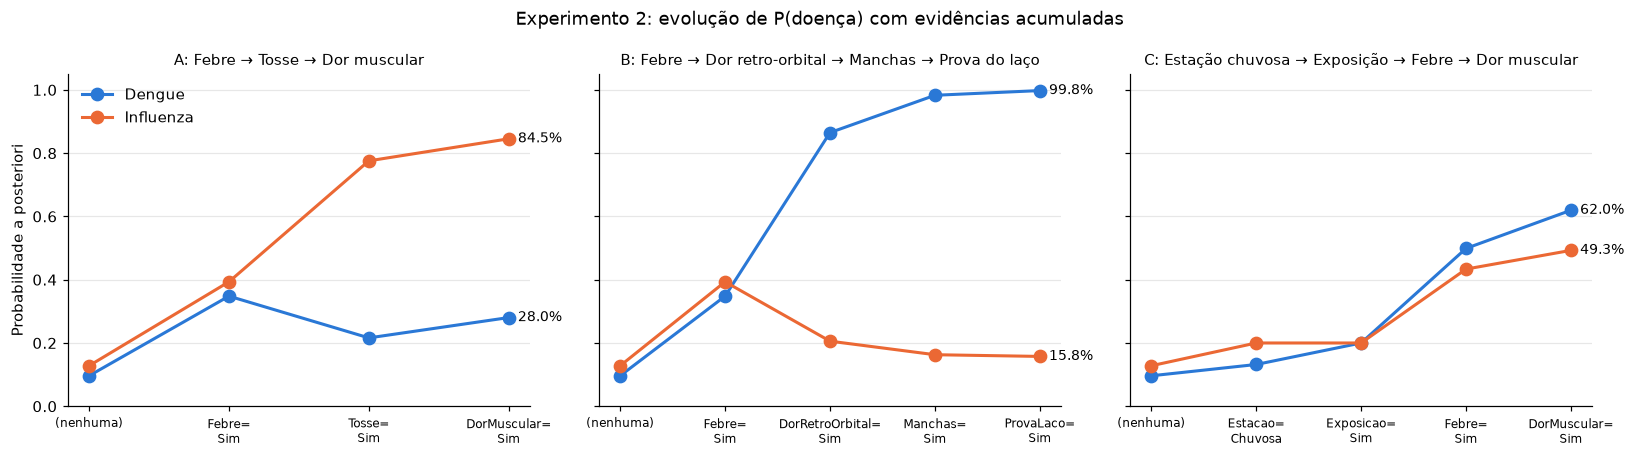

In [13]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (nome, t) in zip(eixos, tabelas_inc.items()):
    passos = np.arange(len(t))
    for coluna, cor, rotulo in [("P(Dengue=Sim)", AZUL, "Dengue"), ("P(Influenza=Sim)", LARANJA, "Influenza")]:
        ax.plot(passos, t[coluna], "-o", color=cor, lw=2, ms=8, label=rotulo)
        ax.annotate(f"{t[coluna].iloc[-1]:.1%}", (passos[-1], t[coluna].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9)
    ax.set_xticks(passos, [e.replace("+ ", "").replace("=", "=\n") for e in t["evidencia"]], fontsize=8)
    ax.set_title(nome.split(":")[0] + ": " + nome.split(": ")[1], fontsize=10)
    ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
eixos[0].set_ylabel("Probabilidade a posteriori")
eixos[0].legend(frameon=False)
fig.suptitle("Experimento 2: evolução de P(doença) com evidências acumuladas")
fig.tight_layout(); fig.savefig(FIGURAS / "q08_exp2_atualizacao_incremental.png", bbox_inches="tight")
plt.show()

## 7. Experimento 3: comparação entre conjuntos de evidências

Cinco perfis de paciente. Todos têm febre; mudam o contexto e os demais achados, inclusive achados negativos (sintoma ausente também é evidência).

In [14]:
perfis = {
    "P1 quadro gripal": {"Febre": "Sim", "Tosse": "Sim", "DorMuscular": "Sim"},
    "P2 quadro clássico de dengue": {"Febre": "Sim", "DorRetroOrbital": "Sim", "Manchas": "Sim", "DorMuscular": "Sim"},
    "P3 febre + dor no corpo, chuva e foco": {"Estacao": "Chuvosa", "Exposicao": "Sim", "Febre": "Sim", "DorMuscular": "Sim"},
    "P4 febre + dor no corpo, seca sem foco": {"Estacao": "Seca", "Exposicao": "Nao", "Febre": "Sim", "DorMuscular": "Sim"},
    "P5 febre, sem tosse e prova do laço +": {"Febre": "Sim", "Tosse": "Nao", "ProvaLaco": "Sim"},
}
exp3 = pd.DataFrame({
    nome: {"P(Dengue=Sim)": distribuicao(ve, "Dengue", ev)["Sim"], "P(Influenza=Sim)": distribuicao(ve, "Influenza", ev)["Sim"]}
    for nome, ev in perfis.items()
}).T
exp3.insert(0, "evidências", [", ".join(f"{k}={v}" for k, v in ev.items()) for ev in perfis.values()])
exp3

,evidências,P(Dengue=Sim),P(Influenza=Sim)
P1 quadro gripal,"Febre=Sim, Tosse=Sim, DorMuscular=Sim",0.2804,0.8455
P2 quadro clássico de dengue,"Febre=Sim, DorRetroOrbital=Sim, Manchas=Sim, D...",0.9909,0.1867
"P3 febre + dor no corpo, chuva e foco","Estacao=Chuvosa, Exposicao=Sim, Febre=Sim, Dor...",0.6196,0.4928
"P4 febre + dor no corpo, seca sem foco","Estacao=Seca, Exposicao=Nao, Febre=Sim, DorMus...",0.2900,0.5637
"P5 febre, sem tosse e prova do laço +","Febre=Sim, Tosse=Nao, ProvaLaco=Sim",0.8619,0.0641


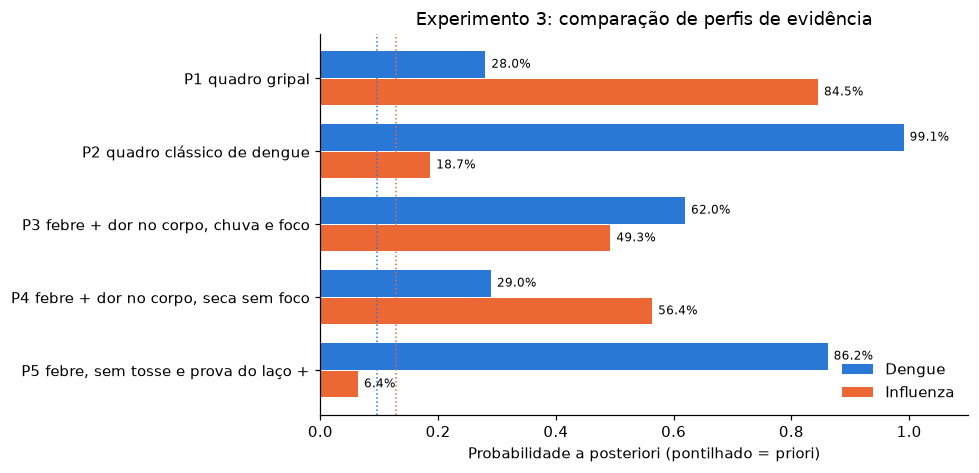

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(exp3))[::-1]
ax.barh(y + 0.19, exp3["P(Dengue=Sim)"], 0.36, color=AZUL, label="Dengue")
ax.barh(y - 0.19, exp3["P(Influenza=Sim)"], 0.36, color=LARANJA, label="Influenza")
for yi, (d, i) in zip(y, exp3[["P(Dengue=Sim)", "P(Influenza=Sim)"]].values):
    ax.text(d + 0.01, yi + 0.19, f"{d:.1%}", va="center", fontsize=8)
    ax.text(i + 0.01, yi - 0.19, f"{i:.1%}", va="center", fontsize=8)
ax.axvline(distribuicao(ve, "Dengue")["Sim"], color=AZUL, ls=":", lw=1)
ax.axvline(distribuicao(ve, "Influenza")["Sim"], color=LARANJA, ls=":", lw=1)
ax.set_yticks(y, exp3.index); ax.set_xlim(0, 1.1); ax.set_xlabel("Probabilidade a posteriori (pontilhado = priori)")
ax.set_title("Experimento 3: comparação de perfis de evidência")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIGURAS / "q08_exp3_comparacao_perfis.png", bbox_inches="tight")
plt.show()

## 8. Experimento 4: explicação mais provável (MAP)

A consulta MAP devolve a combinação conjunta mais provável de Dengue e Influenza. Ela pode diferir de olhar cada marginal isoladamente, por isso mostramos as duas coisas e a probabilidade de cada combinação.

In [16]:
linhas = []
for nome, ev in perfis.items():
    conjunta = ve.query(["Dengue", "Influenza"], evidence=ev, show_progress=False)
    mapa = ve.map_query(["Dengue", "Influenza"], evidence=ev, show_progress=False)
    p_mapa = conjunta.get_value(**mapa)
    linhas.append((nome, f"Dengue={mapa['Dengue']}, Influenza={mapa['Influenza']}", p_mapa,
                   conjunta.get_value(Dengue="Sim", Influenza="Sim")))
pd.DataFrame(linhas, columns=["perfil", "MAP (Dengue, Influenza)", "P(MAP | e)", "P(ambas | e)"])

,perfil,"MAP (Dengue, Influenza)",P(MAP | e),P(ambas | e)
0,P1 quadro gripal,"Dengue=Nao, Influenza=Sim",0.6939,0.1516
1,P2 quadro clássico de dengue,"Dengue=Sim, Influenza=Nao",0.8118,0.1792
2,"P3 febre + dor no corpo, chuva e foco","Dengue=Sim, Influenza=Nao",0.4682,0.1514
3,"P4 febre + dor no corpo, seca sem foco","Dengue=Nao, Influenza=Sim",0.5344,0.0293
4,"P5 febre, sem tosse e prova do laço +","Dengue=Sim, Influenza=Nao",0.8257,0.0361


## 9. Experimento 5: evidência incerta (evidência virtual)

O item b) do enunciado fala em evidências incertas. Um paciente pode dizer que "acha que teve febre" sem ter medido. Isso entra como evidência virtual: um peso de verossimilhança $\lambda = (\lambda_{Sim}, \lambda_{Nao})$ sobre o nó Febre. Com $\lambda = (1, 0)$ recuperamos a evidência dura; com $(0{,}5; 0{,}5)$ o relato não informa nada.

In [17]:
confiancas = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
incerta = pd.DataFrame({
    "P(Dengue=Sim)": [distribuicao(ve, "Dengue", {"DorRetroOrbital": "Sim"}, [evidencia_incerta("Febre", c)])["Sim"] for c in confiancas],
}, index=pd.Index(confiancas, name="peso a favor de Febre=Sim"))
print("Evidência dura adicional: DorRetroOrbital=Sim")
print("Sem informação sobre febre :", round(distribuicao(ve, "Dengue", {"DorRetroOrbital": "Sim"})["Sim"], 4))
print("Febre=Sim certa            :", round(distribuicao(ve, "Dengue", {"DorRetroOrbital": "Sim", "Febre": "Sim"})["Sim"], 4))
incerta

Evidência dura adicional: DorRetroOrbital=Sim
Sem informação sobre febre : 0.5612
Febre=Sim certa            : 0.865


,P(Dengue=Sim)
peso a favor de Febre=Sim,
0.5000,0.5612
0.6000,0.6305
0.7000,0.6951
0.8000,0.7555
0.9000,0.8120
1.0000,0.8650


## 10. Influência de cada evidência e valor da informação

Primeiro, o efeito de cada sintoma isolado sobre P(Dengue): quanto sobe quando o sintoma está presente e quanto cai quando está ausente.

Depois, partindo de um paciente que só relatou febre, qual pergunta ou exame o médico deveria fazer em seguida? A informação mútua $I(\text{Dengue}; C \mid e)$ mede a redução esperada da incerteza (entropia, em bits) sobre a dengue ao observar $C$, ponderando os dois resultados possíveis pela probabilidade de cada um.

In [18]:
sintomas = ["Febre", "DorMuscular", "Tosse", "DorRetroOrbital", "Manchas", "ProvaLaco"]
priori_dengue = distribuicao(ve, "Dengue")["Sim"]
isolado = pd.DataFrame({
    "P(Dengue | C=Sim)": [distribuicao(ve, "Dengue", {s: "Sim"})["Sim"] for s in sintomas],
    "P(Dengue | C=Nao)": [distribuicao(ve, "Dengue", {s: "Nao"})["Sim"] for s in sintomas],
}, index=sintomas)
isolado["razão de verossimilhança +"] = [
    distribuicao(ve, s, {"Dengue": "Sim"})["Sim"] / distribuicao(ve, s, {"Dengue": "Nao"})["Sim"] for s in sintomas
]
print(f"priori P(Dengue=Sim) = {priori_dengue:.4f}")
isolado

priori P(Dengue=Sim) = 0.0963


,P(Dengue | C=Sim),P(Dengue | C=Nao),razão de verossimilhança +
Febre,0.3481,0.0114,5.0100
DorMuscular,0.2853,0.0237,3.7467
Tosse,0.1011,0.0948,1.0552
DorRetroOrbital,0.5612,0.0429,12.0000
Manchas,0.4896,0.0581,9.0000
ProvaLaco,0.4602,0.0631,8.0000


In [19]:
voi = valor_da_informacao(ve, "Dengue", "Sim", {"Febre": "Sim"}, [s for s in sintomas if s != "Febre"])
voi

,variavel,P(C=Sim|e),"P(Dengue=Sim|e,C=Sim)","P(Dengue=Sim|e,C=Nao)",informacao_mutua_bits
0,DorRetroOrbital,0.2414,0.8650,0.1835,0.2728
1,Manchas,0.1892,0.8277,0.2361,0.1676
2,ProvaLaco,0.1718,0.8103,0.2522,0.1372
3,DorMuscular,0.5708,0.5022,0.1431,0.1073
4,Tosse,0.4057,0.2161,0.4382,0.0391


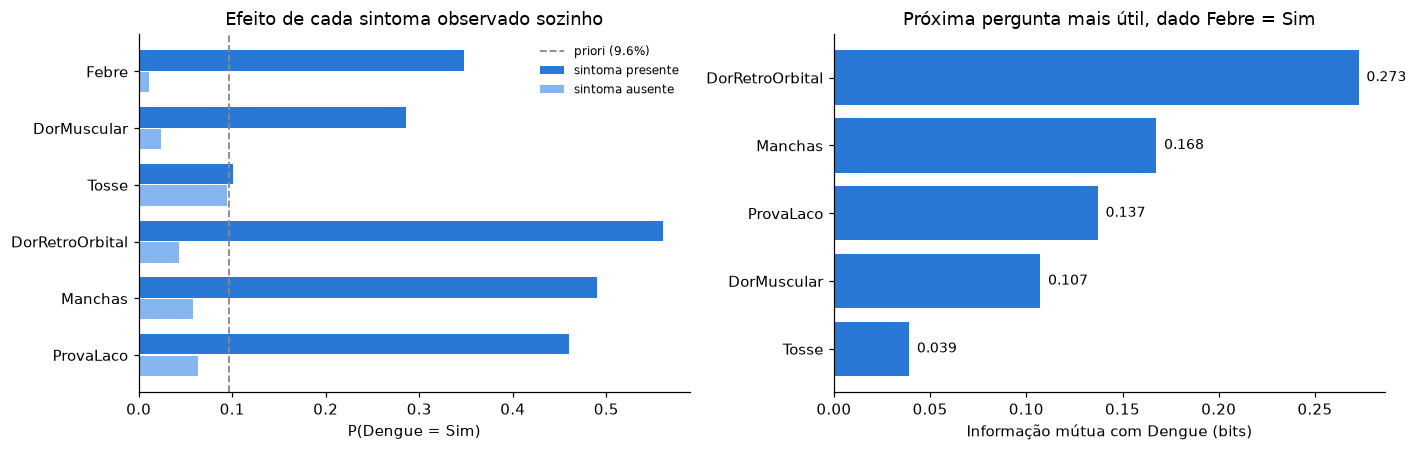

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
y = np.arange(len(isolado))[::-1]
ax1.barh(y + 0.19, isolado["P(Dengue | C=Sim)"], 0.36, color=AZUL, label="sintoma presente")
ax1.barh(y - 0.19, isolado["P(Dengue | C=Nao)"], 0.36, color="#86b6ef", label="sintoma ausente")
ax1.axvline(priori_dengue, color=CINZA, ls="--", lw=1.2, label=f"priori ({priori_dengue:.1%})")
ax1.set_yticks(y, isolado.index); ax1.set_xlabel("P(Dengue = Sim)")
ax1.set_title("Efeito de cada sintoma observado sozinho"); ax1.legend(frameon=False, fontsize=8)

y2 = np.arange(len(voi))[::-1]
ax2.barh(y2, voi["informacao_mutua_bits"], color=AZUL)
for yi, v in zip(y2, voi["informacao_mutua_bits"]):
    ax2.text(v + 0.004, yi, f"{v:.3f}", va="center", fontsize=9)
ax2.set_yticks(y2, voi["variavel"]); ax2.set_xlabel("Informação mútua com Dengue (bits)")
ax2.set_title("Próxima pergunta mais útil, dado Febre = Sim")
fig.tight_layout(); fig.savefig(FIGURAS / "q08_influencia_e_valor_informacao.png", bbox_inches="tight")
plt.show()

## 11. Inferência exata versus aproximada

O Variable Elimination dá o valor exato. Para redes grandes isso pode ficar caro, e aí se usa amostragem. Comparamos dois métodos do pgmpy na consulta $P(\text{Dengue} \mid \text{Febre}=Sim, \text{Tosse}=Sim)$:

- **Amostragem por rejeição**: gera amostras da rede inteira e descarta as que contrariam a evidência. No pgmpy, `size` é o número de amostras *aceitas*; o custo real cresce com $1/P(e)$.
- **Ponderação por verossimilhança** (*likelihood weighting*): fixa as evidências e pondera cada amostra pela verossimilhança delas.

Para cada tamanho rodamos 20 sementes e mostramos média e desvio-padrão da estimativa.

In [21]:
ev_amostra = {"Febre": "Sim", "Tosse": "Sim"}
exato = distribuicao(ve, "Dengue", ev_amostra)["Sim"]
p_evidencia = ve.query(["Febre", "Tosse"], show_progress=False).get_value(Febre="Sim", Tosse="Sim")
print(f"valor exato = {exato:.4f};  P(e) = {p_evidencia:.4f} -> a rejeição descarta ~{1 - p_evidencia:.0%} das amostras geradas")

tamanhos = [50, 100, 200, 500, 1000, 2000, 5000, 10000]
sementes = range(20)
registros = [
    (metodo, n, s, estimar_por_amostragem(rede, "Dengue", "Sim", ev_amostra, n, metodo, s))
    for metodo in ["rejeicao", "ponderacao"] for n in tamanhos for s in sementes
]
amostragem = pd.DataFrame(registros, columns=["metodo", "n", "semente", "estimativa"])
resumo = amostragem.groupby(["metodo", "n"])["estimativa"].agg(media="mean", desvio="std")
resumo["erro_medio_abs"] = amostragem.assign(e=(amostragem["estimativa"] - exato).abs()).groupby(["metodo", "n"])["e"].mean()
resumo.unstack(0)

valor exato = 0.2161;  P(e) = 0.1023 -> a rejeição descarta ~90% das amostras geradas


media              desvio          erro_medio_abs         
metodo ponderacao rejeicao ponderacao rejeicao     ponderacao rejeicao
n                                                                     
50         0.2340   0.2150     0.1446   0.0731         0.1099   0.0542
100        0.2211   0.2175     0.1126   0.0301         0.0865   0.0233
200        0.1827   0.2223     0.0452   0.0354         0.0497   0.0275
500        0.2113   0.2152     0.0405   0.0153         0.0324   0.0128
1000       0.2229   0.2195     0.0374   0.0127         0.0309   0.0099
2000       0.2141   0.2169     0.0187   0.0114         0.0147   0.0092
5000       0.2204   0.2140     0.0142   0.0051         0.0113   0.0046
10000      0.2145   0.2170     0.0076   0.0045         0.0062   0.0038

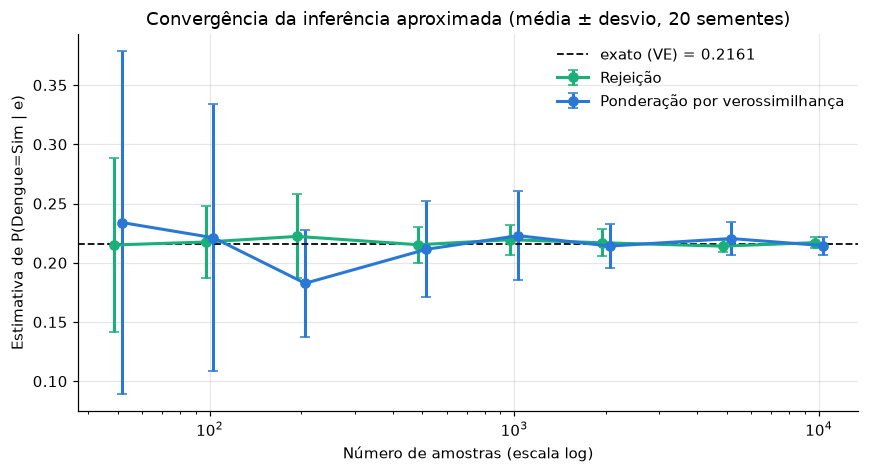

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for metodo, cor, rotulo, desloc in [("rejeicao", VERDE, "Rejeição", 0.97), ("ponderacao", AZUL, "Ponderação por verossimilhança", 1.03)]:
    r = resumo.loc[metodo]
    ax.errorbar(np.array(r.index) * desloc, r["media"], yerr=r["desvio"], fmt="-o", color=cor, lw=2, ms=6, capsize=3, label=rotulo)
ax.axhline(exato, color="#0b0b0b", ls="--", lw=1.2, label=f"exato (VE) = {exato:.4f}")
ax.set_xscale("log"); ax.set_xlabel("Número de amostras (escala log)"); ax.set_ylabel("Estimativa de P(Dengue=Sim | e)")
ax.set_title("Convergência da inferência aproximada (média ± desvio, 20 sementes)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURAS / "q08_convergencia_amostragem.png", bbox_inches="tight")
plt.show()

## 12. Arquivo do projeto: exportação e releitura

O modelo é gravado em quatro formatos padrão na pasta `modelo/`:

- `rede_dengue.bif`: Bayesian Interchange Format (texto);
- `rede_dengue.xml`: XMLBIF;
- `rede_dengue.xdsl`: formato nativo do GeNIe/SMILE;
- `rede_dengue.net`: formato do Hugin, que o GeNIe e outras ferramentas também importam.

Cada arquivo é relido e comparado com a rede original (estrutura, CPTs e uma consulta).

In [23]:
caminhos = exportar_rede(rede, Path("modelo"))
conferencia = []
for extensao, caminho in caminhos.items():
    relida = ler_rede(caminho)
    conferencia.append((
        caminho.name, caminho.stat().st_size,
        set(relida.edges()) == set(rede.edges()),
        all(relida.get_cpds(no) == rede.get_cpds(no) for no in rede.nodes()),
        distribuicao(VariableElimination(relida), "Dengue", ev1)["Sim"],
    ))
pd.DataFrame(conferencia, columns=["arquivo", "bytes", "mesmas arestas", "mesmas CPTs", "P(Dengue | ev. exp. 1)"])

,arquivo,bytes,mesmas arestas,mesmas CPTs,P(Dengue | ev. exp. 1)
0,rede_dengue.bif,1620,True,True,0.9830
1,rede_dengue.xml,2988,True,True,0.9830
2,rede_dengue.xdsl,6529,True,True,0.9830
3,rede_dengue.net,1239,True,True,0.9830


In [24]:
print(caminhos["bif"].read_text()[:900])

network unknown {
}
variable Dengue {
    type discrete [ 2 ] { Sim, Nao };
}
variable DorMuscular {
    type discrete [ 2 ] { Sim, Nao };
}
variable DorRetroOrbital {
    type discrete [ 2 ] { Sim, Nao };
}
variable Estacao {
    type discrete [ 2 ] { Chuvosa, Seca };
}
variable Exposicao {
    type discrete [ 2 ] { Sim, Nao };
}
variable Febre {
    type discrete [ 2 ] { Sim, Nao };
}
variable Influenza {
    type discrete [ 2 ] { Sim, Nao };
}
variable Manchas {
    type discrete [ 2 ] { Sim, Nao };
}
variable ProvaLaco {
    type discrete [ 2 ] { Sim, Nao };
}
variable Tosse {
    type discrete [ 2 ] { Sim, Nao };
}
probability ( Dengue | Exposicao ) {
    ( Sim ) 0.2, 0.8;
    ( Nao ) 0.03, 0.97;

}
probability ( DorMuscular | Dengue, Influenza ) {
    ( Sim, Sim ) 0.95, 0.05;
    ( Sim, Nao ) 0.8, 0.2;
    ( Nao, Sim ) 0.7, 0.3;
    ( Nao, Nao ) 0.15, 0.85;

}
probability ( DorRetr


## 13. Resumo

- A rede tem 10 variáveis, 11 arcos e 2 doenças; todas as CPTs somam 1 e a estrutura passa em `check_model()`.
- O Variable Elimination do pgmpy coincide com a enumeração completa feita com numpy.
- A tosse, somada à febre, *reduz* a probabilidade de dengue porque a influenza passa a explicar a febre (explaining away). Sinais específicos (dor retro-orbital, manchas, prova do laço) elevam bastante a dengue.
- Os métodos de amostragem convergem para o valor exato; com poucos milhares de amostras o desvio já fica em torno de 0,01.
- O modelo foi exportado em BIF, XMLBIF, XDSL e NET, e todos os arquivos foram relidos sem perda.

A discussão completa está no `README.md`.